# EDA02: Hotel Operations Analysis (Elite Hotels International)

**Objective:** Load the `hotel_bookings.csv` dataset and inspect its dimensions, data types, missing values, and duplicate entries before cleaning.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset (one folder up from notebook/)
df = pd.read_csv("../data/hotel_bookings.csv")

print(f"Raw Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

# Check missing values and duplicates
print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"\nDuplicate Rows: {df.duplicated().sum()}")

Raw Dataset Shape: 119390 rows, 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Missing Values:
children         4
country        488
agent        16340
company     112593
dtype: int64

Duplicate Rows: 31994


## Data Cleaning & Preprocessing

**Steps:**
1. Fill missing `children` values with `0` and convert to integer.
2. Fill missing `country` values with `'Unknown'`.
3. Keep `agent` and `company` `NaN` values intact so non-null counts accurately reflect bookings made through travel agents or companies.
4. Convert `reservation_status_date` to datetime format.
5. Check and remove duplicate rows.

In [3]:
# 1. Handle missing values
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')

# 2. Convert date column to datetime
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# 3. Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Cleaned Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Cleaned Dataset Shape: 87396 rows, 32 columns

Remaining Missing Values:
agent      12193
company    82137
dtype: int64


**Conclusion:** After filling missing values in `children` (with `0`) and `country` (with `'Unknown'`), converting `reservation_status_date` to datetime format, and removing `31,994` duplicate rows, the cleaned dataset contains **87,396 unique bookings and 32 columns**. Missing values in `agent` (12,193) and `company` (82,137) are intentionally retained so non-null counts accurately identify travel agency and corporate bookings.

## Part 1: Basic-Level Questions

### Basic Question 1: What is the average lead time for bookings?

**Objective:** Calculate the mean (and summary statistics) of the `lead_time` column to understand how many days in advance guests typically book their stays.

In [11]:
# Calculate average lead time and summary statistics
avg_lead_time = df['lead_time'].mean()
median_lead_time = df['lead_time'].median()

print(f"Average Lead Time: {avg_lead_time:.2f} days")
print(f"Median Lead Time: {median_lead_time:.2f} days")

# Full summary statistics for lead_time
display(df['lead_time'].describe().round(2).to_frame(name='Lead_Time_Days'))

Average Lead Time: 79.89 days
Median Lead Time: 49.00 days


,Lead_Time_Days
count,87396.00
mean,79.89
std,86.05
min,0.00
25%,11.00
50%,49.00
75%,125.00
max,737.00


**Conclusion:** Guests book their stays an average of **79.89 days (~2.6 months)** in advance, with a **median lead time of 49.00 days (~7 weeks)**. While **25%** of bookings are made within **11 days** of arrival (last-minute travelers), early-bird bookings extending up to **737 days** pull the overall average noticeably higher than the median.

### Basic Question 2: What is the distribution of bookings by hotel type?

**Objective:** Count the number and percentage share of bookings for each hotel type (`City Hotel` vs. `Resort Hotel`) and visualize the distribution with a bar chart.

,Booking_Count,Percentage (%)
hotel,,
City Hotel,53428,61.13
Resort Hotel,33968,38.87


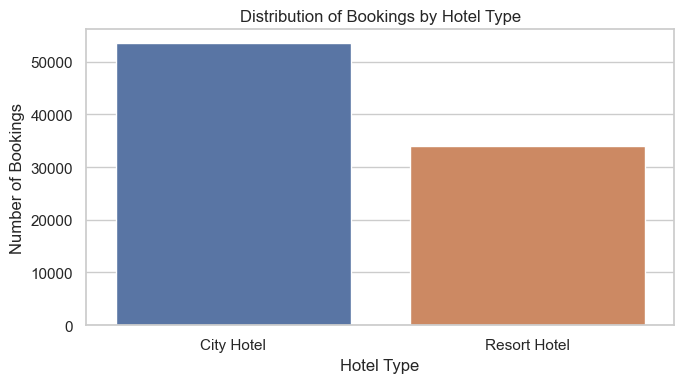

In [12]:
# Count bookings and calculate percentage share by hotel type
hotel_counts = df['hotel'].value_counts()
hotel_pct = (df['hotel'].value_counts(normalize=True) * 100).round(2)

hotel_dist = pd.DataFrame({
    'Booking_Count': hotel_counts,
    'Percentage (%)': hotel_pct
})
display(hotel_dist)

# Bar chart of bookings by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(x=hotel_dist.index, y=hotel_dist['Booking_Count'], hue=hotel_dist.index, legend=False)
plt.title('Distribution of Bookings by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** accounts for the majority of reservations with **53,428 bookings (61.13%)**, compared to **33,968 bookings (38.87%)** for **Resort Hotel**—nearly a **1.6-to-1 ratio** favoring urban hotel properties across the dataset.

### Basic Question 3: How many bookings were canceled?

**Objective:** Sum the values in the `is_canceled` column (`1` = Canceled, `0` = Not Canceled) to calculate total cancellations and the overall cancellation rate.

In [13]:
# Count total canceled and non-canceled bookings
total_canceled = df['is_canceled'].sum()
total_bookings = len(df)
cancellation_rate = (total_canceled / total_bookings) * 100

print(f"Total Canceled Bookings: {total_canceled}")
print(f"Total Non-Canceled Bookings: {total_bookings - total_canceled}")
print(f"Overall Cancellation Rate: {cancellation_rate:.2f}%")

# Summary breakdown table
cancel_summary = pd.DataFrame({
    'Status': ['Not Canceled (0)', 'Canceled (1)'],
    'Count': [total_bookings - total_canceled, total_canceled],
    'Percentage (%)': [round(100 - cancellation_rate, 2), round(cancellation_rate, 2)]
})
display(cancel_summary)

Total Canceled Bookings: 24025
Total Non-Canceled Bookings: 63371
Overall Cancellation Rate: 27.49%


,Status,Count,Percentage (%)
0,Not Canceled (0),63371,72.51
1,Canceled (1),24025,27.49


**Conclusion:** Out of **87,396 unique bookings**, a total of **24,025 bookings (27.49%)** were canceled, while **63,371 bookings (72.51%)** were not canceled—meaning more than **1 in 4 reservations** results in a cancellation.

### Basic Question 4: What is the most common arrival month for bookings?

**Objective:** Find the mode and monthly booking counts of `arrival_date_month` to identify peak arrival seasons.

Most Common Arrival Month: August


,Booking_Count
arrival_date_month,
January,4693
February,6098
March,7513
April,7908
May,8355
June,7765
July,10057
August,11257
September,6690


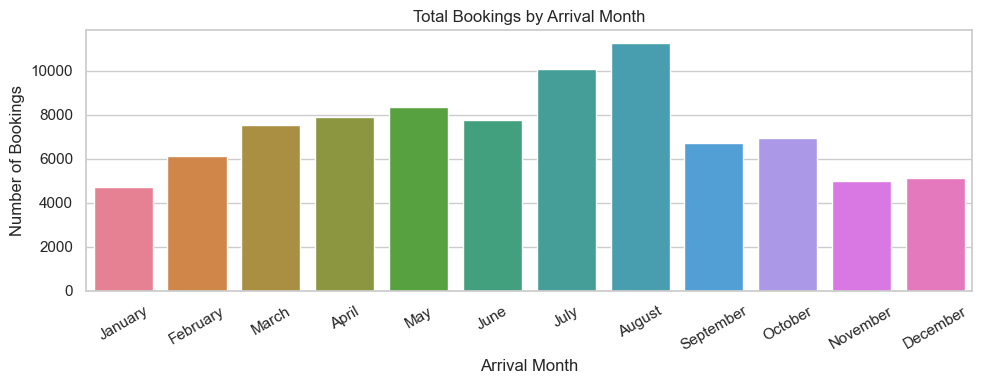

In [15]:
# Find the most common arrival month (mode) and full monthly counts
most_common_month = df['arrival_date_month'].mode()[0]
print(f"Most Common Arrival Month: {most_common_month}")

# Order months chronologically from January to December
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
monthly_arrivals = df['arrival_date_month'].value_counts().reindex(month_order)
display(monthly_arrivals.to_frame(name='Booking_Count'))

# Plot bookings by arrival month
plt.figure(figsize=(10, 4))
sns.barplot(x=monthly_arrivals.index, y=monthly_arrivals.values, hue=monthly_arrivals.index, legend=False)
plt.title('Total Bookings by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Conclusion:** **August** is the most common arrival month with **11,257 bookings (12.88% of all arrivals)**, followed closely by **July (10,057 bookings)**—highlighting a clear peak summer travel window. By contrast, winter months experience the lowest demand, dipping to **4,693 bookings in January** and **4,995 in November**.

### Basic Question 5: What is the average number of special requests per booking?

**Objective:** Calculate the mean and distribution of `total_of_special_requests` to understand guest service expectations across bookings.

In [16]:
# Calculate average number of special requests per booking
avg_special_requests = df['total_of_special_requests'].mean()
print(f"Average Special Requests per Booking: {avg_special_requests:.2f}")

# Distribution of special requests per booking
requests_dist = pd.DataFrame({
    'Booking_Count': df['total_of_special_requests'].value_counts().sort_index(),
    'Percentage (%)': (df['total_of_special_requests'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(requests_dist)

Average Special Requests per Booking: 0.70


,Booking_Count,Percentage (%)
total_of_special_requests,,
0,43894,50.22
1,29017,33.20
2,11812,13.52
3,2317,2.65
4,320,0.37
5,36,0.04


**Conclusion:** Guests submit an average of **0.70 special requests per booking**. Just over half of all reservations (**50.22%**, 43,894 bookings) include **no special requests**, while **33.20%** (29,017 bookings) include **1 request** and **16.58%** include **2 to 5 requests**—meaning nearly half of all arriving guests require at least one personalized accommodation or service arrangement.

### Basic Question 6: Which country has the highest number of bookings?

**Objective:** Count the bookings by `country` to identify the top country of origin and the major guest demographics.

Country with Highest Number of Bookings: PRT (27453 bookings)


,Booking_Count,Percentage (%)
country,,
PRT,27453,31.41
GBR,10433,11.94
FRA,8837,10.11
ESP,7252,8.30
DEU,5387,6.16
ITA,3066,3.51
IRL,3016,3.45
BEL,2081,2.38
BRA,1995,2.28


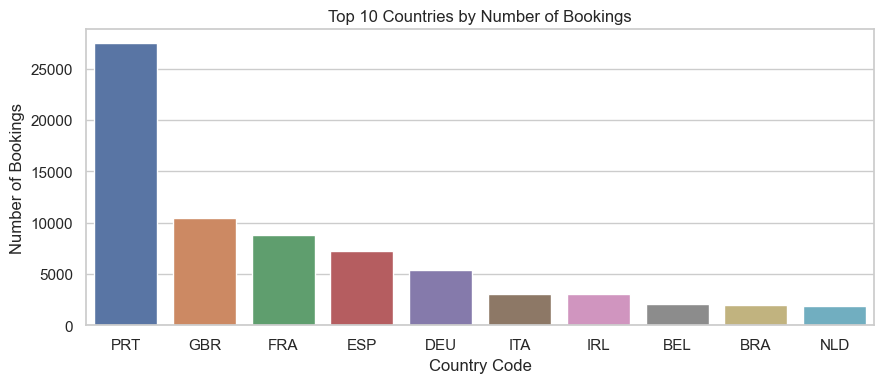

In [17]:
# Identify the top country and top 10 countries by booking count
top_country = df['country'].value_counts().index[0]
top_country_count = df['country'].value_counts().iloc[0]
print(f"Country with Highest Number of Bookings: {top_country} ({top_country_count} bookings)")

# Top 10 countries table with booking count and percentage share
top_10_countries = pd.DataFrame({
    'Booking_Count': df['country'].value_counts().head(10),
    'Percentage (%)': (df['country'].value_counts(normalize=True).head(10) * 100).round(2)
})
display(top_10_countries)

# Bar chart of Top 10 countries
plt.figure(figsize=(9, 4))
sns.barplot(x=top_10_countries.index, y=top_10_countries['Booking_Count'], hue=top_10_countries.index, legend=False)
plt.title('Top 10 Countries by Number of Bookings')
plt.xlabel('Country Code')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **Portugal (`PRT`)** generates the highest volume of reservations with **27,453 bookings (31.41% of all bookings)**, followed by the **United Kingdom (`GBR`, 10,433 bookings, 11.94%)**, **France (`FRA`, 8,837, 10.11%)**, **Spain (`ESP`, 7,252, 8.30%)**, and **Germany (`DEU`, 5,387, 6.16%)**. Together, these top 5 Western European countries represent **67.92%** of total guest demand.

### Basic Question 7: What is the average daily rate (ADR) for each hotel type?

**Objective:** Group the dataset by `hotel` and calculate the mean, median, and standard deviation of `adr` to compare daily room rate performance between `City Hotel` and `Resort Hotel`.

,Booking_Count,Mean_ADR,Median_ADR,Std_Dev
hotel,,,,
City Hotel,53428,110.99,105.3,48.06
Resort Hotel,33968,99.03,79.5,63.77


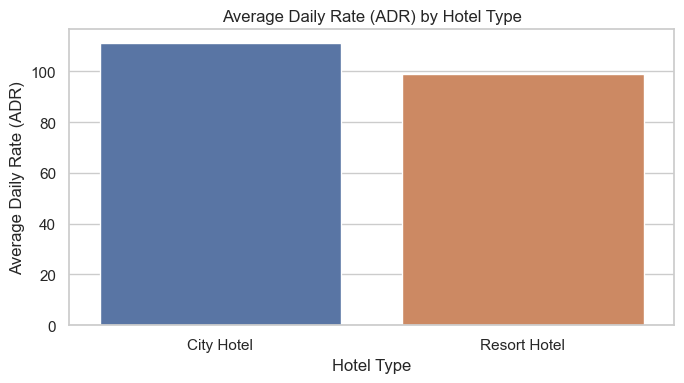

In [18]:
# Calculate ADR summary statistics by hotel type
adr_by_hotel = df.groupby('hotel')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median',
    Std_Dev='std'
).round(2)

display(adr_by_hotel)

# Bar chart comparing Mean ADR by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(x=adr_by_hotel.index, y=adr_by_hotel['Mean_ADR'], hue=adr_by_hotel.index, legend=False)
plt.title('Average Daily Rate (ADR) by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** achieves a higher Average Daily Rate (ADR) of **110.99** (median: **105.30**) compared to **99.03** (median: **79.50**) for **Resort Hotel**—a difference of **11.96 per night**. At the same time, **Resort Hotel** shows much wider rate variability (standard deviation of **63.77** vs. **48.06** for City Hotel), reflecting sharper seasonal price swings between off-peak winter months and peak summer resort demand.

### Basic Question 8: What percentage of guests required car parking spaces?

**Objective:** Calculate the number and percentage of bookings where `required_car_parking_spaces > 0` to assess guest parking demand.


In [19]:
# Calculate bookings requiring at least one car parking space
parking_required = (df['required_car_parking_spaces'] > 0).sum()
total_bookings = len(df)
parking_pct = (parking_required / total_bookings) * 100

print(f"Bookings Requiring Car Parking: {parking_required} out of {total_bookings}")
print(f"Percentage of Guests Requiring Parking: {parking_pct:.2f}%")

# Breakdown by number of parking spaces requested
parking_breakdown = pd.DataFrame({
    'Booking_Count': df['required_car_parking_spaces'].value_counts().sort_index(),
    'Percentage (%)': (df['required_car_parking_spaces'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(parking_breakdown)

Bookings Requiring Car Parking: 7313 out of 87396
Percentage of Guests Requiring Parking: 8.37%


,Booking_Count,Percentage (%)
required_car_parking_spaces,,
0,80083,91.63
1,7280,8.33
2,28,0.03
3,3,0.00
8,2,0.00


**Conclusion:** Only **8.37% of guests (7,313 out of 87,396 bookings)** required car parking spaces, while the remaining **91.63% (80,083 bookings)** required none. Nearly all parking demand comes from single-vehicle guests (**7,280 bookings, 8.33%**), indicating that current parking infrastructure needs to accommodate roughly **1 in every 12 reservations** rather than the full guest base.

### Basic Question 9: What is the average stay duration in week nights and weekend nights?

**Objective:** Calculate the mean and summary statistics of `stays_in_week_nights` and `stays_in_weekend_nights` (along with total stay duration) to understand typical guest stay lengths.

In [20]:
# Calculate average stay duration in week nights and weekend nights
avg_week_nights = df['stays_in_week_nights'].mean()
avg_weekend_nights = df['stays_in_weekend_nights'].mean()
avg_total_nights = (df['stays_in_week_nights'] + df['stays_in_weekend_nights']).mean()

print(f"Average Week Nights Stayed: {avg_week_nights:.2f} nights")
print(f"Average Weekend Nights Stayed: {avg_weekend_nights:.2f} nights")
print(f"Average Total Stay Duration: {avg_total_nights:.2f} nights")

# Summary statistics table
stay_summary = df[['stays_in_week_nights', 'stays_in_weekend_nights']].describe().round(2)
display(stay_summary)

Average Week Nights Stayed: 2.63 nights
Average Weekend Nights Stayed: 1.01 nights
Average Total Stay Duration: 3.63 nights


,stays_in_week_nights,stays_in_weekend_nights
count,87396.00,87396.00
mean,2.63,1.01
std,2.05,1.03
min,0.00,0.00
25%,1.00,0.00
50%,2.00,1.00
75%,4.00,2.00
max,50.00,19.00


**Conclusion:** Guests stay an average of **2.63 week nights** (median: **2.00**) and **1.01 weekend nights** (median: **1.00**), resulting in an overall average stay duration of **3.63 nights**. Because **75%** of bookings span **4 or fewer week nights** and **2 or fewer weekend nights**, the majority of hotel demand consists of short 3-to-4-night leisure or business trips rather than extended stays.

### Basic Question 10: How many bookings were made through travel agents?

**Objective:** Count the non-null values in the `agent` column to determine how many bookings were facilitated by travel agents versus direct/non-agent bookings.

In [21]:
# Count bookings made through travel agents (non-null values in 'agent')
agent_bookings = df['agent'].notnull().sum()
non_agent_bookings = df['agent'].isnull().sum()
total_bookings = len(df)
agent_pct = (agent_bookings / total_bookings) * 100

print(f"Bookings Made Through Travel Agents: {agent_bookings} out of {total_bookings}")
print(f"Percentage of Agent Bookings: {agent_pct:.2f}%")

# Breakdown table
agent_summary = pd.DataFrame({
    'Booking_Channel_Type': ['Travel Agent (agent present)', 'Direct / Non-Agent (agent missing)'],
    'Booking_Count': [agent_bookings, non_agent_bookings],
    'Percentage (%)': [round(agent_pct, 2), round(100 - agent_pct, 2)]
})
display(agent_summary)

Bookings Made Through Travel Agents: 75203 out of 87396
Percentage of Agent Bookings: 86.05%


,Booking_Channel_Type,Booking_Count,Percentage (%)
0,Travel Agent (agent present),75203,86.05
1,Direct / Non-Agent (agent missing),12193,13.95


**Conclusion:** A large majority of reservations—**75,203 out of 87,396 bookings (86.05%)**—were made through **travel agents**, whereas only **12,193 bookings (13.95%)** came through direct or non-agent channels. This heavy reliance on third-party travel agencies highlights the importance of maintaining strong agency partnerships while also building direct-booking incentives to reduce commission costs.

## Part 2: Medium-Level Questions

### Medium Question 1: What is the cancellation rate for each hotel type?

**Objective:** Group the dataset by `hotel` and calculate the total bookings, canceled bookings, and average cancellation rate (`is_canceled` mean) for `City Hotel` versus `Resort Hotel`.

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
hotel,,,
City Hotel,53428,16049,30.04
Resort Hotel,33968,7976,23.48


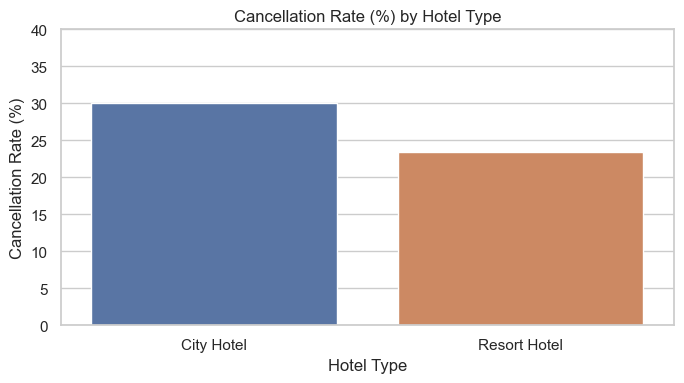

In [22]:
# Group by hotel type and calculate total bookings, canceled count, and cancellation rate (%)
cancel_by_hotel = df.groupby('hotel')['is_canceled'].agg(
    Total_Bookings='count',
    Canceled_Bookings='sum',
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
)

display(cancel_by_hotel)

# Bar chart of cancellation rate by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(
    x=cancel_by_hotel.index,
    y=cancel_by_hotel['Cancellation_Rate'],
    hue=cancel_by_hotel.index,
    legend=False
)
plt.title('Cancellation Rate (%) by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 40)
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** experiences a substantially higher cancellation rate of **30.04%** (**16,049** canceled out of **53,428** bookings) compared to **23.48%** (**7,976** canceled out of **33,968** bookings) for **Resort Hotel**—a **6.56 percentage-point gap**. City Hotel properties therefore require stricter deposit policies, cancellation deadlines, or targeted overbooking buffers to protect room occupancy.

### Medium Question 2: What is the average ADR per market segment?

**Objective:** Group the dataset by `market_segment` and calculate the booking count, mean ADR, and median ADR to compare daily rate performance across customer segments.

,Booking_Count,Mean_ADR,Median_ADR
market_segment,,,
Online TA,51618,118.17,110.70
Direct,11804,116.58,106.60
Aviation,227,100.17,95.00
Offline TA/TO,13889,81.76,79.05
Groups,4942,74.86,68.00
Corporate,4212,68.15,65.00
Undefined,2,15.00,15.00
Complementary,702,3.05,0.00


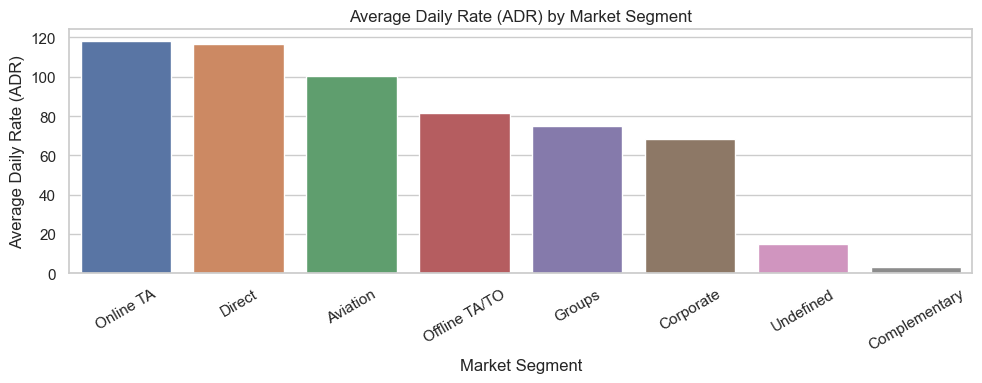

In [23]:
# Calculate average and median ADR per market segment
adr_by_segment = df.groupby('market_segment')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median'
).round(2).sort_values(by='Mean_ADR', ascending=False)

display(adr_by_segment)

# Bar chart of Mean ADR by market segment
plt.figure(figsize=(10, 4))
sns.barplot(
    x=adr_by_segment.index,
    y=adr_by_segment['Mean_ADR'],
    hue=adr_by_segment.index,
    legend=False
)
plt.title('Average Daily Rate (ADR) by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Conclusion:** **Online TA** generates the highest Average Daily Rate at **118.17** (median: **110.70**) across **51,618 bookings**, followed closely by **Direct** bookings at **116.58** (median: **106.60**). By contrast, bulk and negotiated channels such as **Offline TA/TO (81.76)**, **Groups (74.86)**, and **Corporate (68.15)** command substantially lower daily rates—showing that **Direct** bookings deliver nearly the same high nightly revenue as Online TAs without third-party commission fees.

### Medium Question 3: What is the relationship between lead time and cancellation rate?

**Objective:** Explore the correlation between `lead_time` and `is_canceled` using a scatter plot and summary statistics to see whether bookings made further in advance are more likely to be canceled.

Correlation between Lead Time and Cancellation: 0.1848


,Booking_Count,Mean_Lead_Time,Median_Lead_Time
is_canceled,,,
0,63371,70.10,38.0
1,24025,105.72,80.0


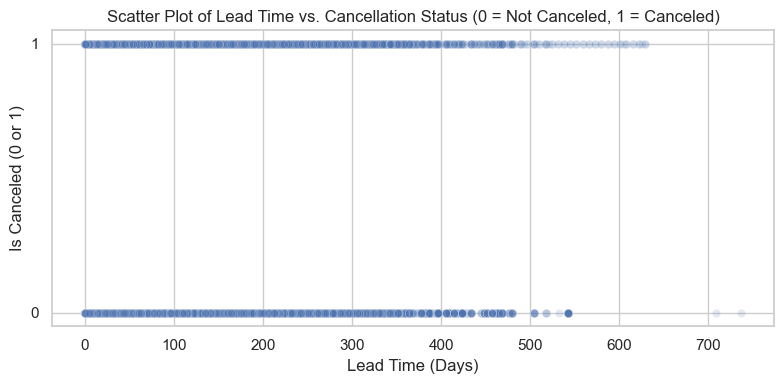

In [24]:
# Calculate correlation and compare average/median lead time by cancellation status
corr_lead_cancel = df['lead_time'].corr(df['is_canceled'])
print(f"Correlation between Lead Time and Cancellation: {corr_lead_cancel:.4f}")

lead_by_cancel = df.groupby('is_canceled')['lead_time'].agg(
    Booking_Count='count',
    Mean_Lead_Time='mean',
    Median_Lead_Time='median'
).round(2)
display(lead_by_cancel)

# Scatter plot of lead_time vs is_canceled (as specified in the PDF hint)
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='lead_time', y='is_canceled', alpha=0.15)
plt.title('Scatter Plot of Lead Time vs. Cancellation Status (0 = Not Canceled, 1 = Canceled)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Is Canceled (0 or 1)')
plt.yticks([0, 1])
plt.tight_layout()
plt.show()

**Conclusion:** There is a positive correlation (**r = 0.1848**) between lead time and booking cancellations. Canceled reservations were booked an average of **105.72 days** in advance (median: **80.0 days**)—more than **50% longer** than non-canceled reservations, which averaged **70.10 days** (median: **38.0 days**). Because plans change far more frequently over longer booking windows, early-bird bookings carry substantially higher cancellation risk and should require partial deposits or automated pre-arrival reconfirmation reminders.

### Medium Question 4: Which distribution channel has the highest number of bookings?

**Objective:** Count the bookings and percentage share across `distribution_channel` to identify the primary booking acquisition channel.

Distribution Channel with Highest Bookings: TA/TO (69141 bookings)


,Booking_Count,Percentage (%)
distribution_channel,,
TA/TO,69141,79.11
Direct,12988,14.86
Corporate,5081,5.81
GDS,181,0.21
Undefined,5,0.01


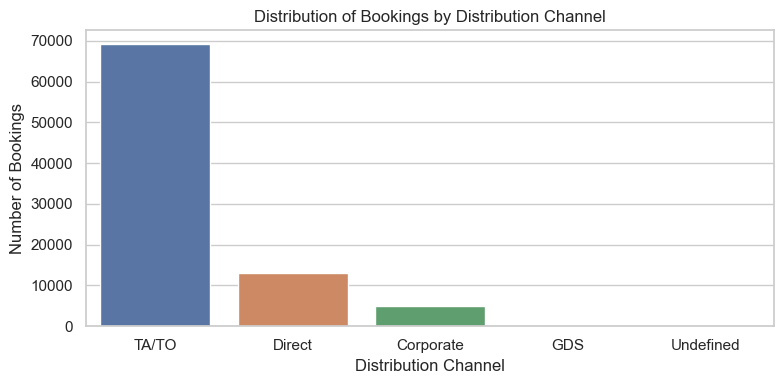

In [25]:
# Count bookings and percentage share by distribution channel
channel_dist = pd.DataFrame({
    'Booking_Count': df['distribution_channel'].value_counts(),
    'Percentage (%)': (df['distribution_channel'].value_counts(normalize=True) * 100).round(2)
})

top_channel = channel_dist.index[0]
top_channel_count = channel_dist['Booking_Count'].iloc[0]
print(f"Distribution Channel with Highest Bookings: {top_channel} ({top_channel_count} bookings)")

display(channel_dist)

# Bar chart of bookings by distribution channel
plt.figure(figsize=(8, 4))
sns.barplot(
    x=channel_dist.index,
    y=channel_dist['Booking_Count'],
    hue=channel_dist.index,
    legend=False
)
plt.title('Distribution of Bookings by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **TA/TO (Travel Agents / Tour Operators)** dominates booking acquisition with **69,141 bookings (79.11%)**, followed by **Direct** bookings at **12,988 (14.86%)** and **Corporate** bookings at **5,081 (5.81%)**. Because nearly four-fifths of reservations flow through third-party intermediaries, Elite Hotels International can meaningfully improve net profit margins by converting repeat `TA/TO` guests into `Direct` bookers through loyalty perks.

### Medium Question 5: What is the average number of previous cancellations by hotel type?

**Objective:** Group the dataset by `hotel` and calculate the mean and total of `previous_cancellations` to compare repeat cancellation history across `City Hotel` and `Resort Hotel` guests.

,Booking_Count,Total_Previous_Cancellations,Mean_Previous_Cancellations
hotel,,,
City Hotel,53428,1911,0.0358
Resort Hotel,33968,747,0.0220


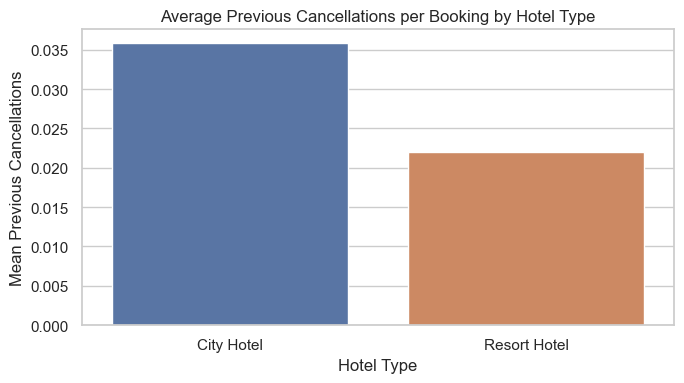

In [26]:
# Calculate average and total previous cancellations by hotel type
prev_cancel_by_hotel = df.groupby('hotel')['previous_cancellations'].agg(
    Booking_Count='count',
    Total_Previous_Cancellations='sum',
    Mean_Previous_Cancellations=lambda x: round(x.mean(), 4)
)

display(prev_cancel_by_hotel)

# Bar chart of average previous cancellations by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(
    x=prev_cancel_by_hotel.index,
    y=prev_cancel_by_hotel['Mean_Previous_Cancellations'],
    hue=prev_cancel_by_hotel.index,
    legend=False
)
plt.title('Average Previous Cancellations per Booking by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Mean Previous Cancellations')
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** guests have a higher average number of previous cancellations at **0.0358 per booking** (**1,911** total previous cancellations across **53,428** bookings) compared to **0.0220 per booking** (**747** total across **33,968** bookings) at **Resort Hotel**—over **62% higher** per reservation. This aligns with City Hotel's higher overall cancellation rate (**30.04%** vs. **23.48%**) and reinforces the value of flagging repeat cancelers for stricter booking terms.

### Medium Question 6: What is the trend of bookings over the years?

**Objective:** Group the dataset by `arrival_date_year` (and break down by `hotel` type) to analyze annual booking volumes and year-over-year growth from 2015 to 2017.

,Total_Bookings,Percentage (%)
arrival_date_year,,
2015,13313,15.23
2016,42391,48.50
2017,31692,36.26


hotel,City Hotel,Resort Hotel
arrival_date_year,,
2015,6550,6763
2016,26759,15632
2017,20119,11573


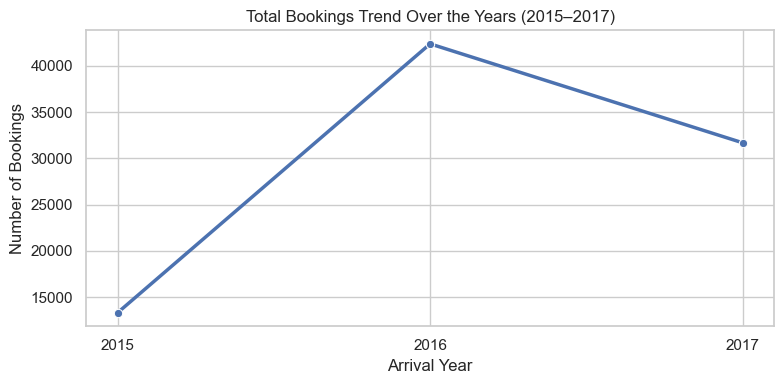

In [27]:
# Count total bookings and percentage share by arrival year
yearly_bookings = pd.DataFrame({
    'Total_Bookings': df['arrival_date_year'].value_counts().sort_index(),
    'Percentage (%)': (df['arrival_date_year'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(yearly_bookings)

# Breakdown by year and hotel type
yearly_by_hotel = df.groupby(['arrival_date_year', 'hotel']).size().unstack()
display(yearly_by_hotel)

# Line plot of booking trend over the years
plt.figure(figsize=(8, 4))
sns.lineplot(
    x=yearly_bookings.index.astype(str),
    y=yearly_bookings['Total_Bookings'],
    marker='o',
    linewidth=2.5
)
plt.title('Total Bookings Trend Over the Years (2015–2017)')
plt.xlabel('Arrival Year')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** Booking volume peaked in **2016** with **42,391 reservations (48.50% of the dataset)**, compared to **13,313 bookings (15.23%)** in **2015** and **31,692 bookings (36.26%)** in **2017**. Note that **2016** is the only full calendar year captured in the dataset (12 months), whereas **2015** covers July–December (6 months) and **2017** covers January–August (8 months)—on a monthly run-rate basis, demand actually climbed steadily from **~2,219 bookings/month in 2015** to **~3,533/month in 2016** and **~3,962/month in 2017**, driven predominantly by strong growth in **City Hotel** reservations.

### Medium Question 7: Which customer type has the highest ADR?

**Objective:** Group the dataset by `customer_type` and calculate the booking count, mean ADR, and median ADR to identify which customer segment generates the highest average daily room rate.

Customer Type with Highest Mean ADR: Transient (110.14)


,Booking_Count,Mean_ADR,Median_ADR
customer_type,,,
Transient,71986,110.14,102.00
Contract,3139,92.75,90.90
Transient-Party,11727,87.68,81.28
Group,544,84.36,75.00


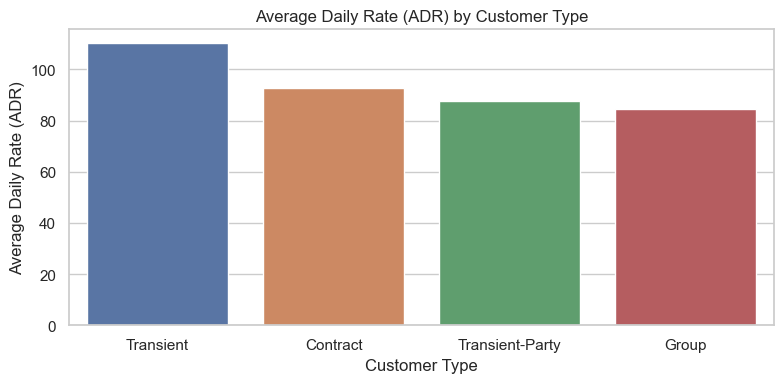

In [28]:
# Calculate ADR summary statistics by customer type
adr_by_customer = df.groupby('customer_type')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median'
).round(2).sort_values(by='Mean_ADR', ascending=False)

top_customer_type = adr_by_customer.index[0]
top_customer_adr = adr_by_customer['Mean_ADR'].iloc[0]
print(f"Customer Type with Highest Mean ADR: {top_customer_type} ({top_customer_adr})")

display(adr_by_customer)

# Bar chart of Mean ADR by customer type
plt.figure(figsize=(8, 4))
sns.barplot(
    x=adr_by_customer.index,
    y=adr_by_customer['Mean_ADR'],
    hue=adr_by_customer.index,
    legend=False
)
plt.title('Average Daily Rate (ADR) by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.tight_layout()
plt.show()

**Conclusion:** **Transient** guests generate the highest Average Daily Rate at **110.14** (median: **102.00**) while also representing the largest customer segment (**71,986 bookings, 82.37%** of all reservations). By contrast, negotiated and multi-room segments—**Contract (92.75)**, **Transient-Party (87.68)**, and **Group (84.36)**—trade lower nightly rates for bulk or recurring room commitments.